In [ ]:
# Importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Reading the WHO Life Expectancy Dataset
import kagglehub
import warnings
warnings.filterwarnings("ignore")

# Download latest version
path = kagglehub.dataset_download("kumarajarshi/life-expectancy-who")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/kumarajarshi/life-expectancy-who/versions/1


In [ ]:
data = pd.read_csv( "/root/.cache/kagglehub/datasets/kumarajarshi/life-expectancy-who/versions/1/Life Expectancy Data.csv")
# data = pd.read_csv( path + "/Life Expectancy Data.csv")


In [ ]:
# 1. Display the first rows(head()) to understand the structure
# It is made of a Pandas DataFrame
data.head(20)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
5,Afghanistan,2010,Developing,58.8,279.0,74,0.01,79.679367,66.0,1989,...,66.0,9.20,66.0,0.1,553.328940,2883167.0,18.4,18.4,0.448,9.2
6,Afghanistan,2009,Developing,58.6,281.0,77,0.01,56.762217,63.0,2861,...,63.0,9.42,63.0,0.1,445.893298,284331.0,18.6,18.7,0.434,8.9
7,Afghanistan,2008,Developing,58.1,287.0,80,0.03,25.873925,64.0,1599,...,64.0,8.33,64.0,0.1,373.361116,2729431.0,18.8,18.9,0.433,8.7
8,Afghanistan,2007,Developing,57.5,295.0,82,0.02,10.910156,63.0,1141,...,63.0,6.73,63.0,0.1,369.835796,26616792.0,19.0,19.1,0.415,8.4
9,Afghanistan,2006,Developing,57.3,295.0,84,0.03,17.171518,64.0,1990,...,58.0,7.43,58.0,0.1,272.563770,2589345.0,19.2,19.3,0.405,8.1


In [ ]:
# 2. Check the Dataset Information -> info()
# Rows, Columns and thier Datatypes

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [ ]:
# 3. Checking the size of the dataset -> shape attribute

data.shape[0]

2938

In [ ]:
# 3. SANITY CHECKS

# a) Finding the missing records -> isnull().sum()
data.isnull().sum()

# percentage of the missing values
# More than 50%, the column is deleted
# Total Empties / Total Records * 100
# Total Empties -> data.isnull().sum()
# Total Records -> data.shape[0]

data.isnull().sum()/data.shape[0]*100

,0
Country,0.000000
Year,0.000000
Status,0.000000
Life expectancy,0.340368
Adult Mortality,0.340368
infant deaths,0.000000
Alcohol,6.603131
percentage expenditure,0.000000
Hepatitis B,18.822328
Measles,0.000000


In [ ]:
# b) Checking for Duplicated Records -> duplicated().sum()
data.duplicated().sum()


0

In [ ]:
# Step4: EXPLORATORY DATA ANALYSIS

# a) descriptive statistics
# Numerical
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2.007519e+03,4.613841e+00,2000.00000,2004.000000,2.008000e+03,2.012000e+03,2.015000e+03
Life expectancy,2928.0,6.922493e+01,9.523867e+00,36.30000,63.100000,7.210000e+01,7.570000e+01,8.900000e+01
Adult Mortality,2928.0,1.647964e+02,1.242921e+02,1.00000,74.000000,1.440000e+02,2.280000e+02,7.230000e+02
infant deaths,2938.0,3.030395e+01,1.179265e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03
Alcohol,2744.0,4.602861e+00,4.052413e+00,0.01000,0.877500,3.755000e+00,7.702500e+00,1.787000e+01
percentage expenditure,2938.0,7.382513e+02,1.987915e+03,0.00000,4.685343,6.491291e+01,4.415341e+02,1.947991e+04
Hepatitis B,2385.0,8.094046e+01,2.507002e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01
Measles,2938.0,2.419592e+03,1.146727e+04,0.00000,0.000000,1.700000e+01,3.602500e+02,2.121830e+05
BMI,2904.0,3.832125e+01,2.004403e+01,1.00000,19.300000,4.350000e+01,5.620000e+01,8.730000e+01
under-five deaths,2938.0,4.203574e+01,1.604455e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03


In [ ]:
# Counts of the Categorical(Text) Columns

data.describe(include='object').T

,count,unique,top,freq
Country,2938,193,Afghanistan,16
Status,2938,2,Developing,2426


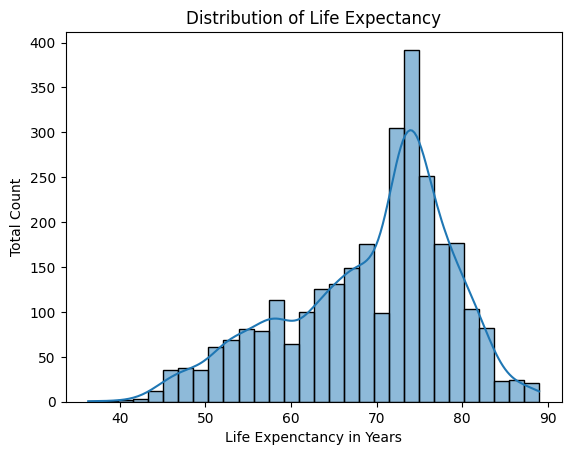

In [ ]:
# Data Distribution Using a Histogram -> histplot()
# For a Single Column
sns.histplot(data = data, x = 'Life expectancy ', kde=True)
plt.xlabel('Life Expenctancy in Years')
plt.ylabel('Total Count')
plt.title('Distribution of Life Expectancy')
plt.show()

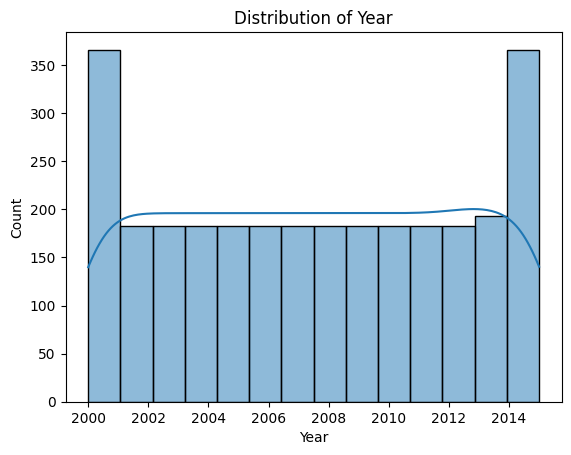

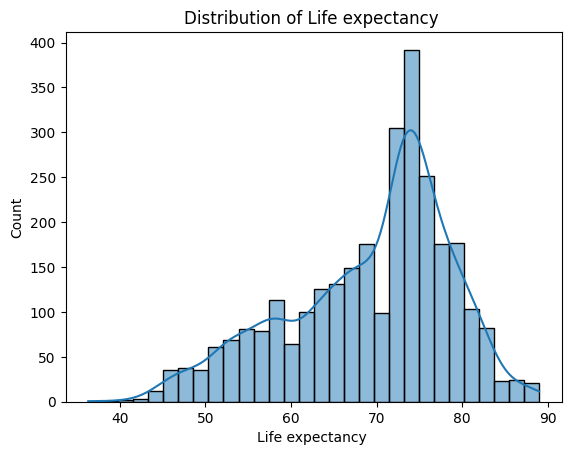

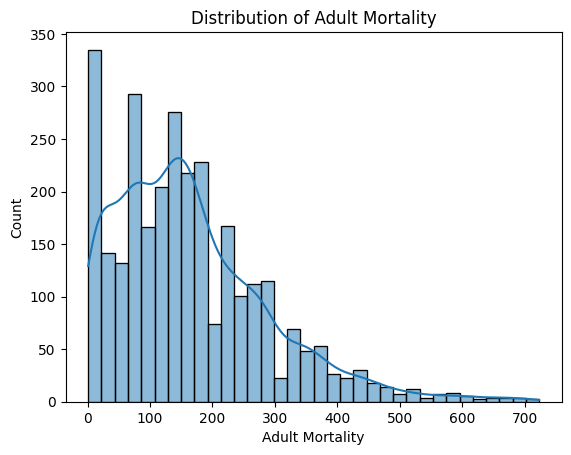

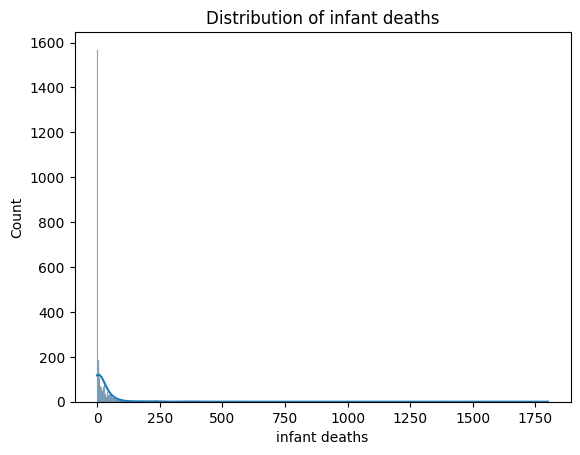

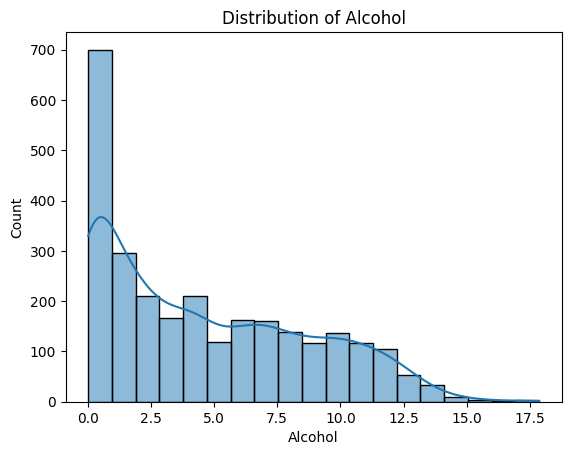

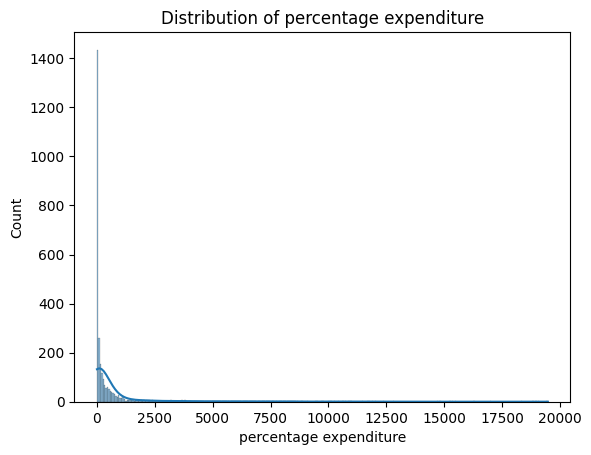

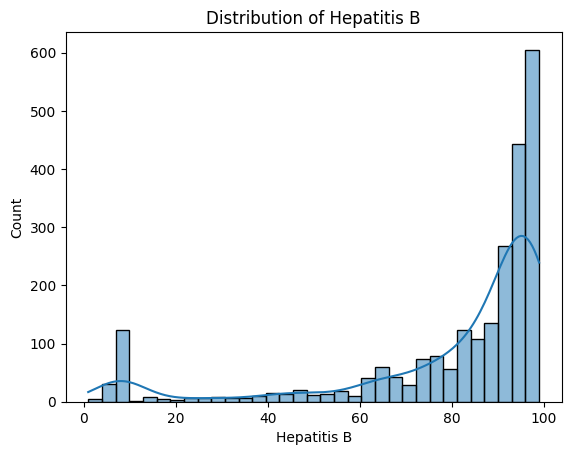

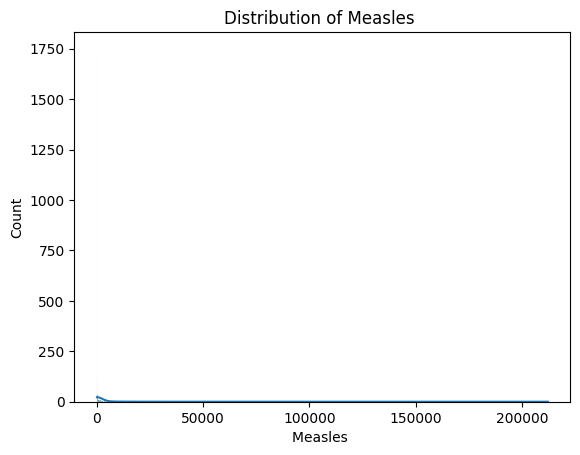

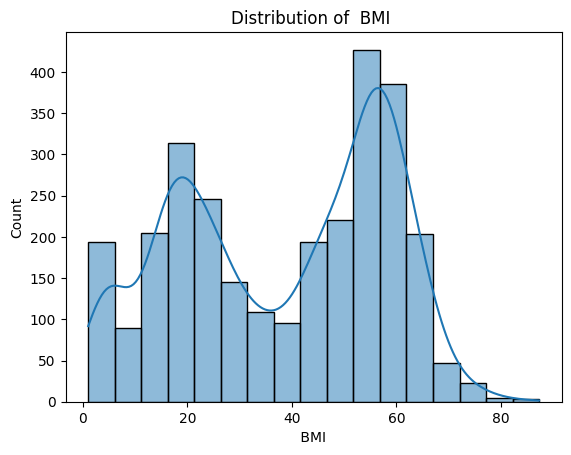

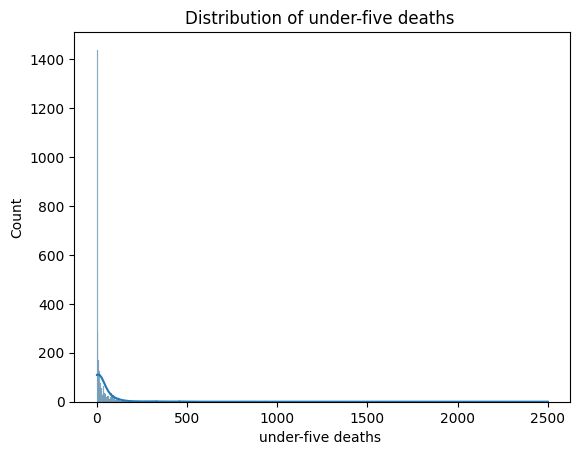

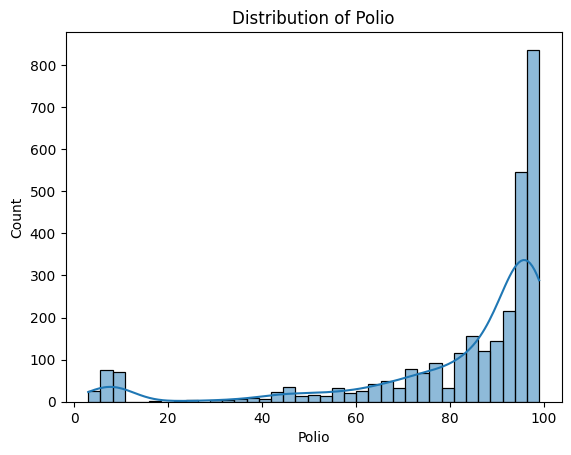

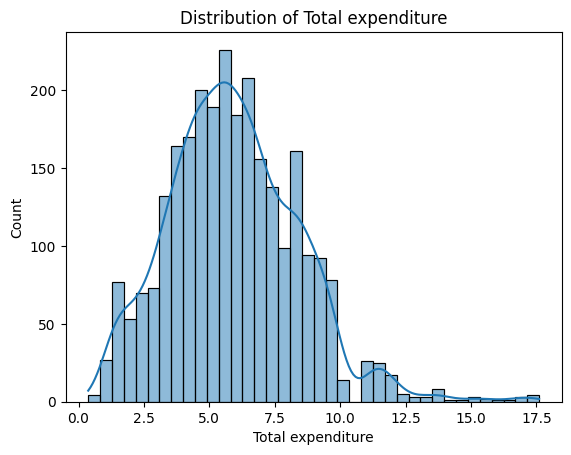

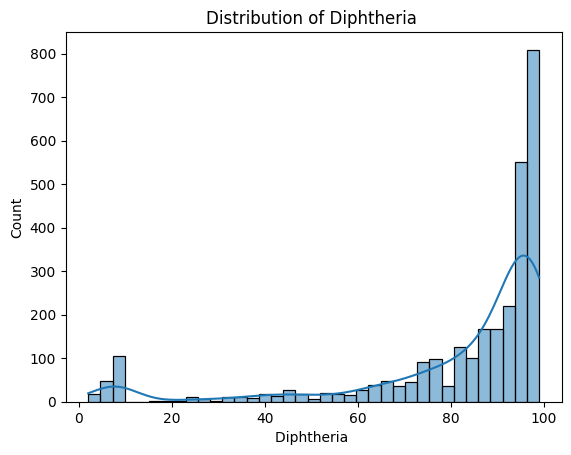

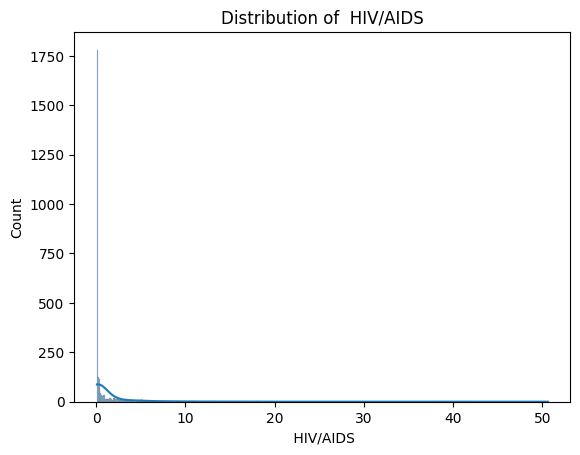

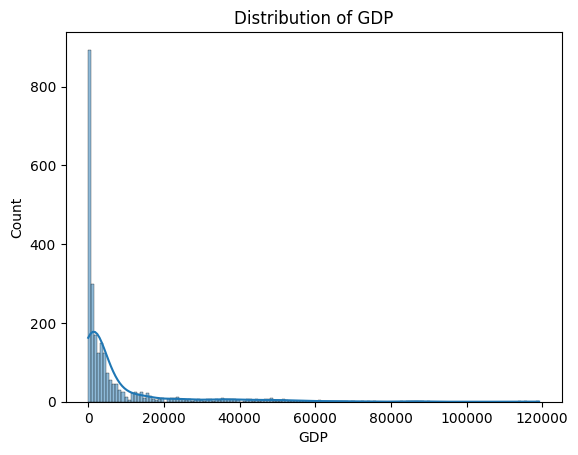

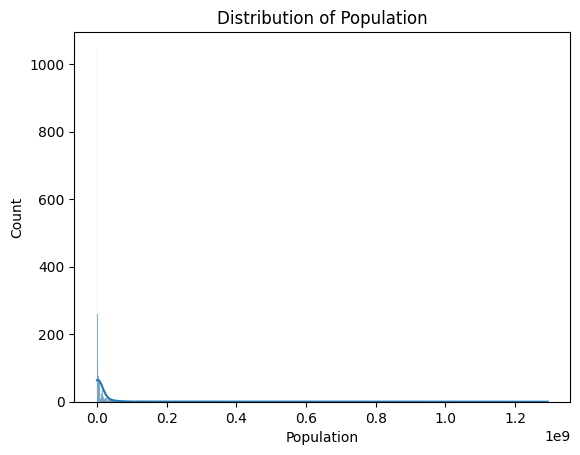

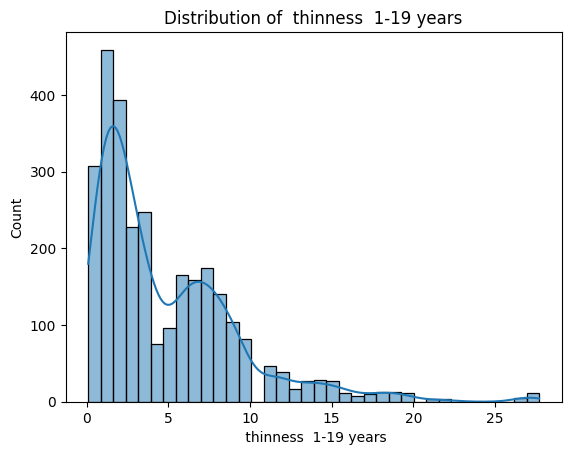

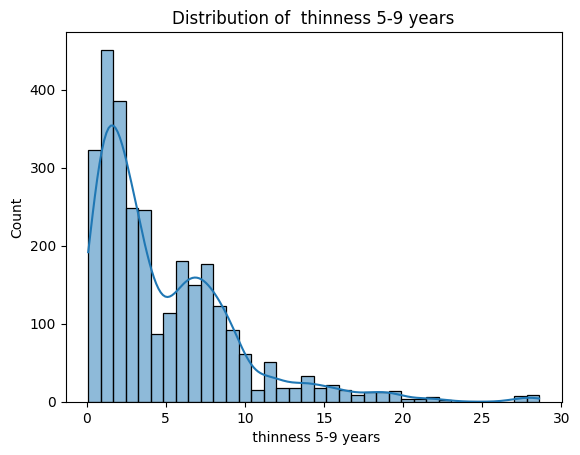

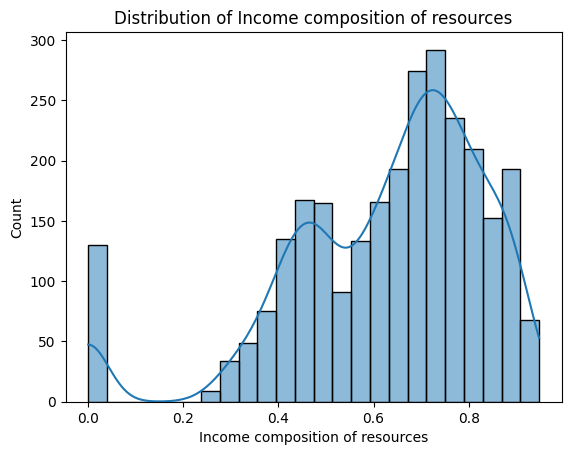

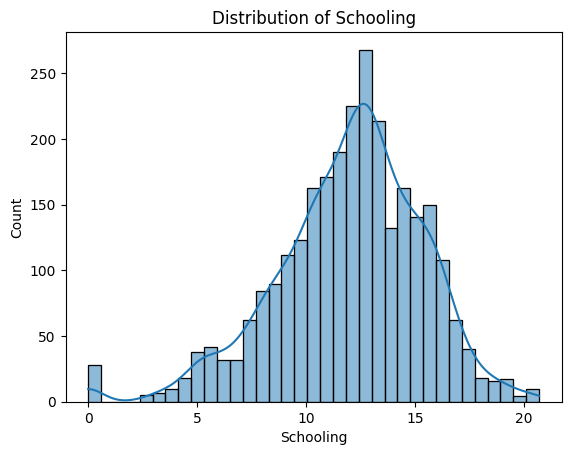

In [ ]:
# Distribution for All the Numeric Columns
# Therefore, we need a for loop, to iterate through the list of numeric columns
# print(data.select_dtypes(include='number').columns)

for i in data.select_dtypes(include='number').columns:
    sns.histplot(data = data, x = i, kde=True)
    plt.title(f'Distribution of {i}')
    plt.show()



In [ ]:
# OUTLIERS DETECTION USING BOXPLOTS
# CORRELATION ANALYSIS USING HEATMAPS

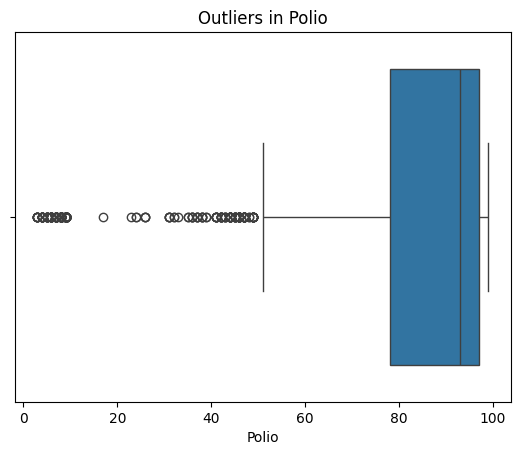

Index(['Year', 'Life expectancy ', 'Adult Mortality', 'infant deaths',
       'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ',
       'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ',
       ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years',
       ' thinness 5-9 years', 'Income composition of resources', 'Schooling'],
      dtype='object')


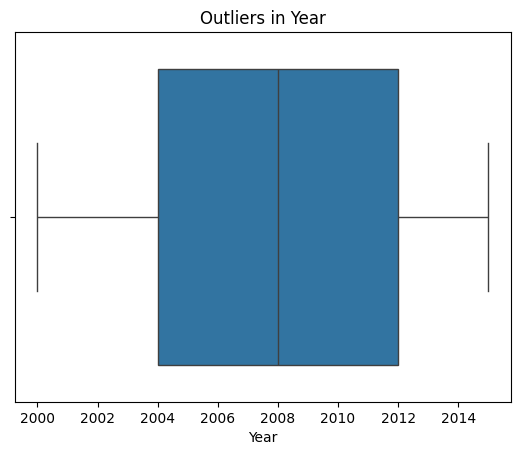

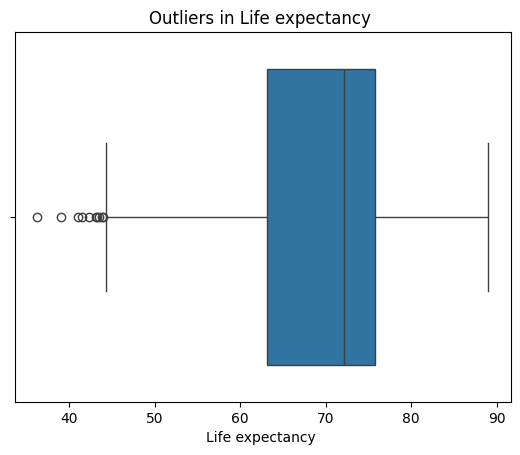

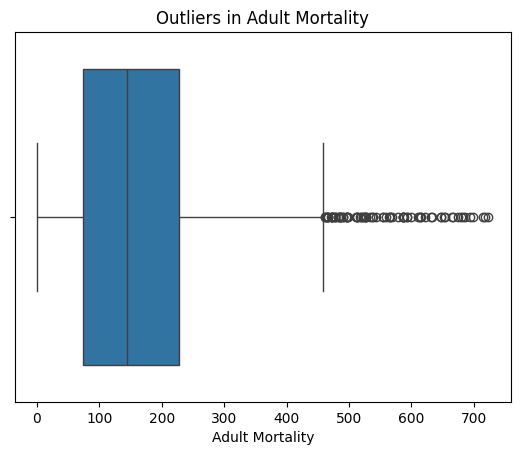

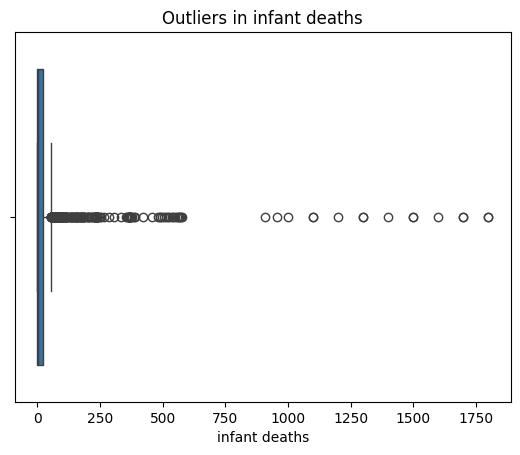

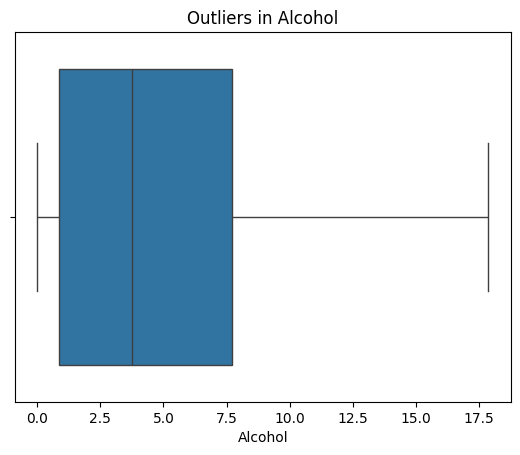

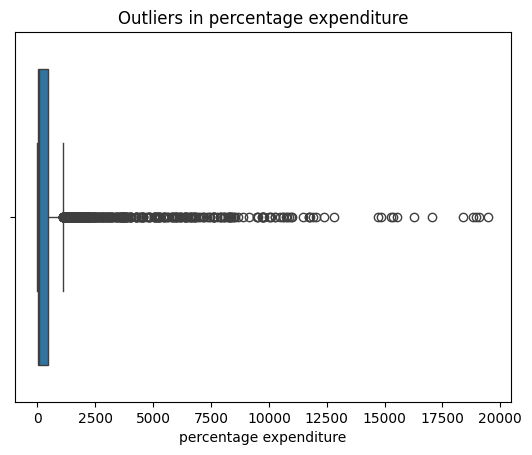

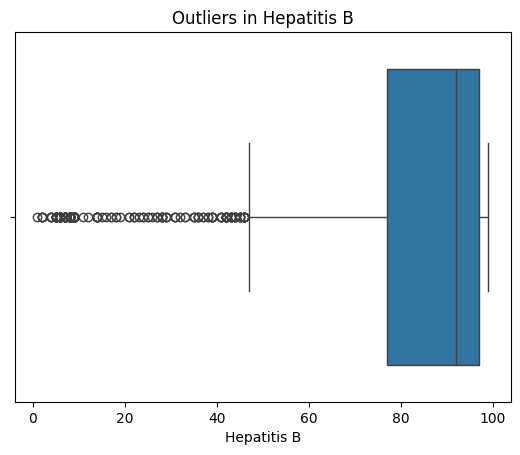

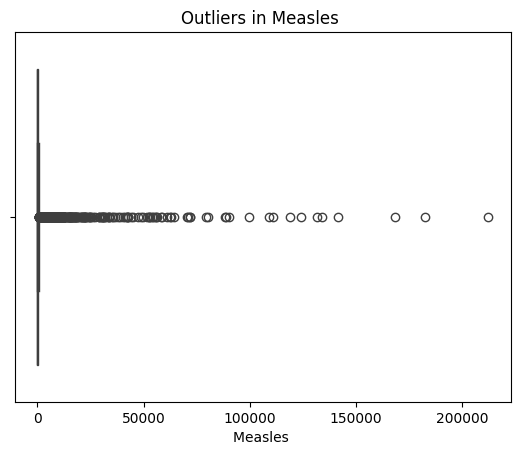

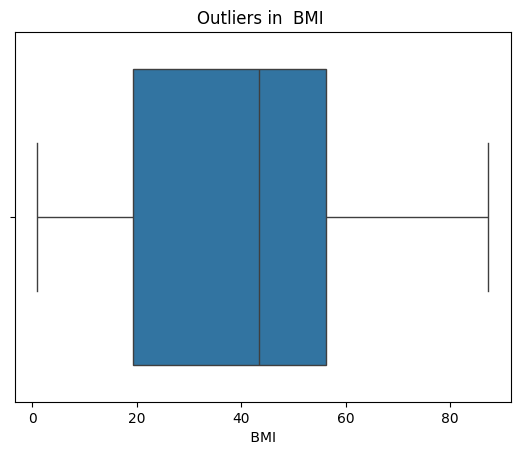

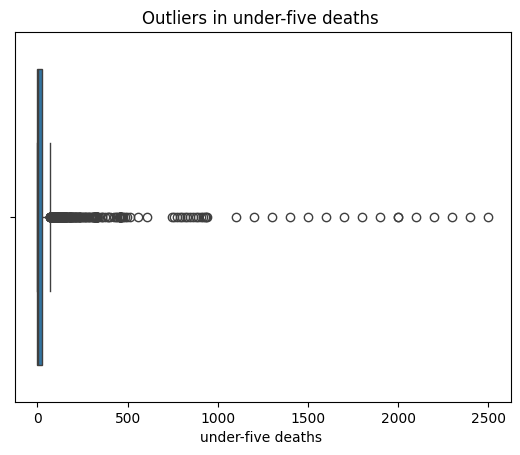

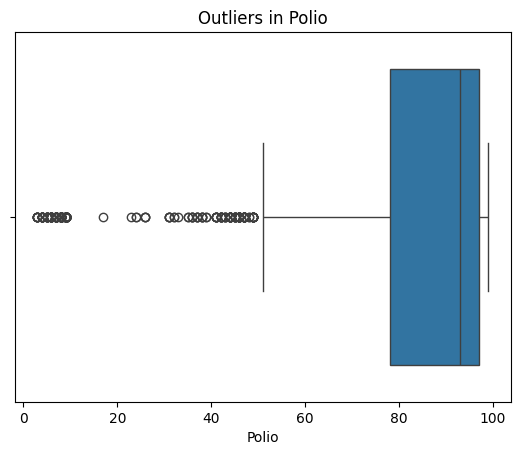

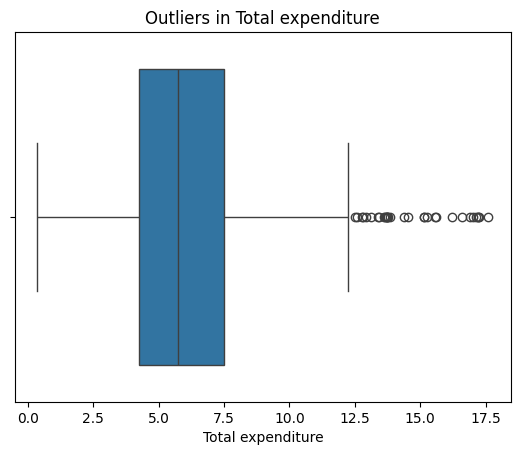

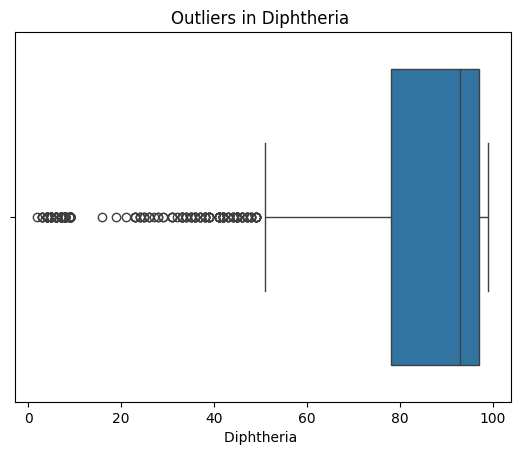

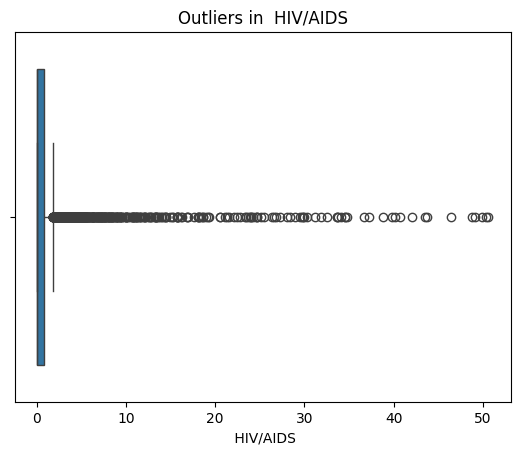

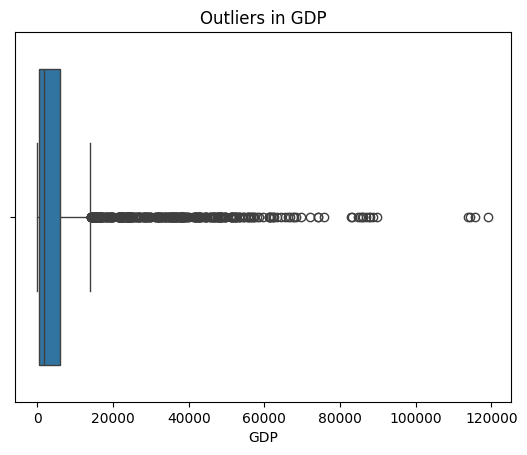

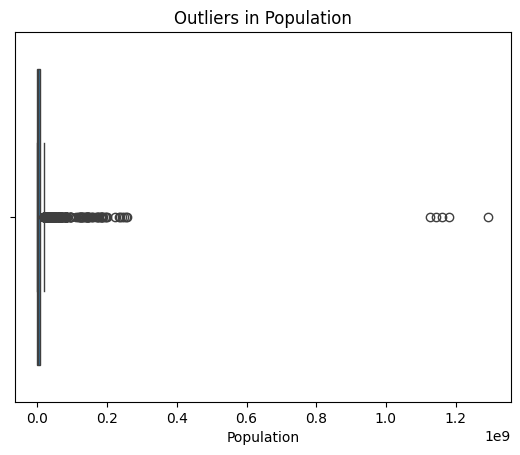

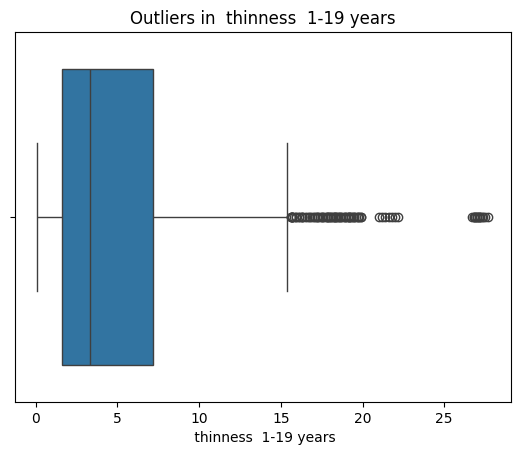

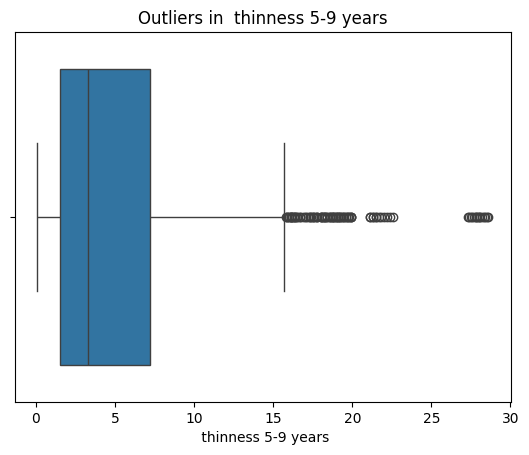

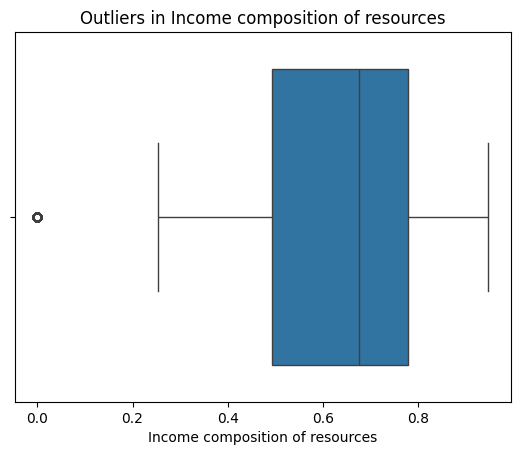

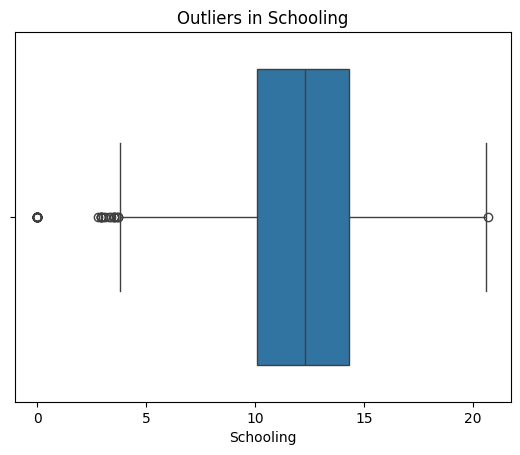

In [ ]:
# OUTLIERS:
# Outliers are extreme values that deviate significantly from other observations.
# They can be caused by errors in data entry or genuine variations in the dataset.

# Age column -> 200
# Life expectancy column -> 150
# Life expenctancy column -> 1


# DETECTING OUTLIERS USING BOX-PLOTS
# E,g Life Expenctancy
sns.boxplot(data = data, x = 'Polio')
plt.title('Outliers in Polio')
plt.show()


# DETECTING OUTLIERS FOR ALL THE NUMERIC COLUMNS
print(data.select_dtypes(include='number').columns)

for i in data.select_dtypes(include='number').columns:
    sns.boxplot(data = data, x = i)
    plt.title(f'Outliers in {i}')
    plt.show()

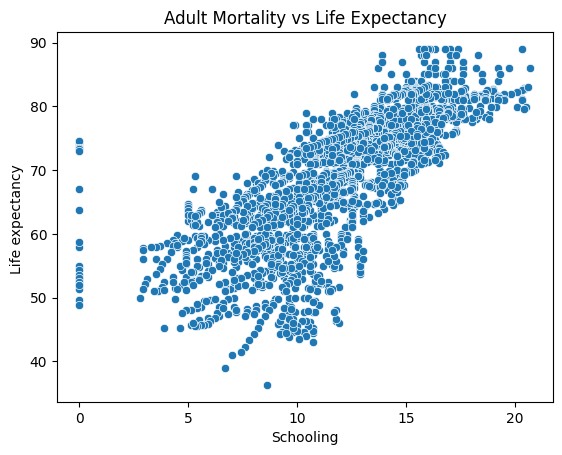

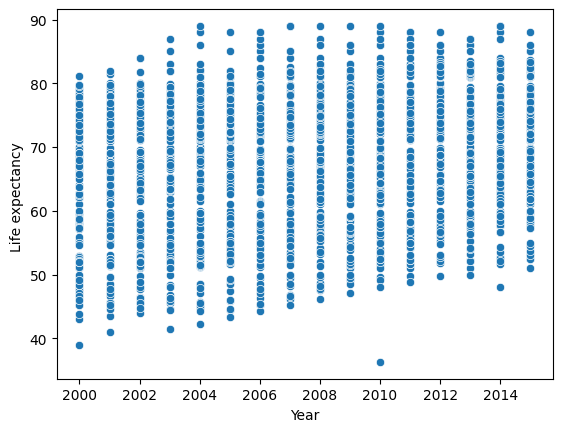

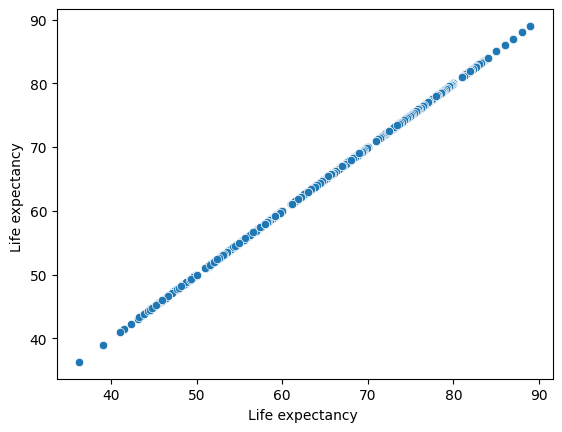

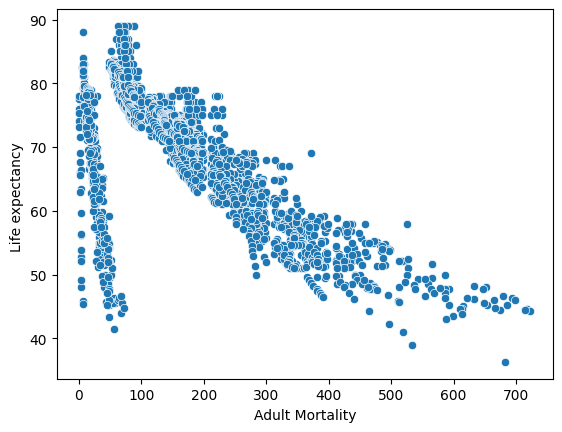

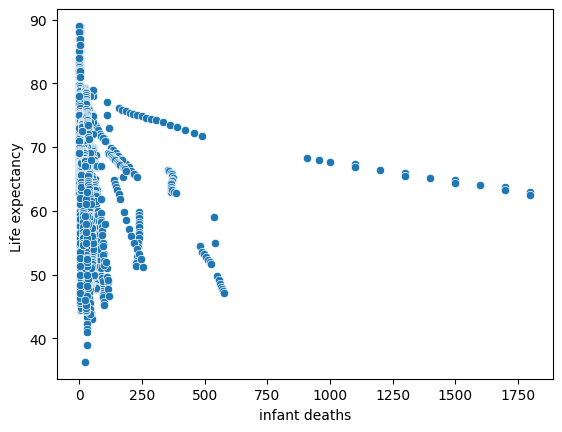

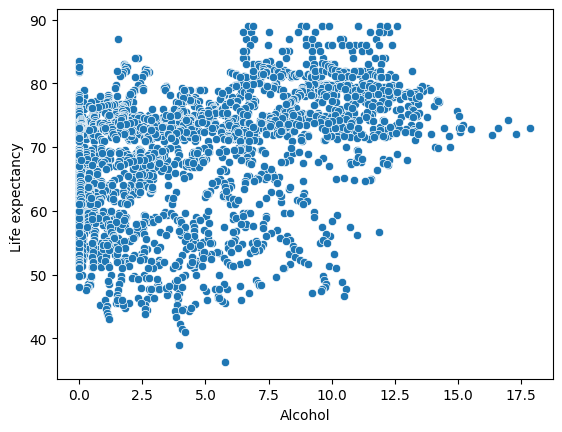

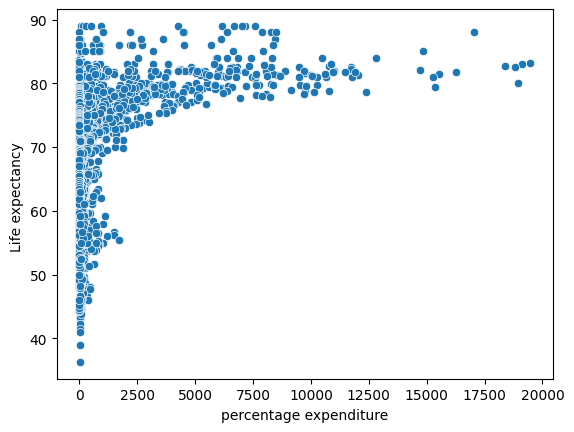

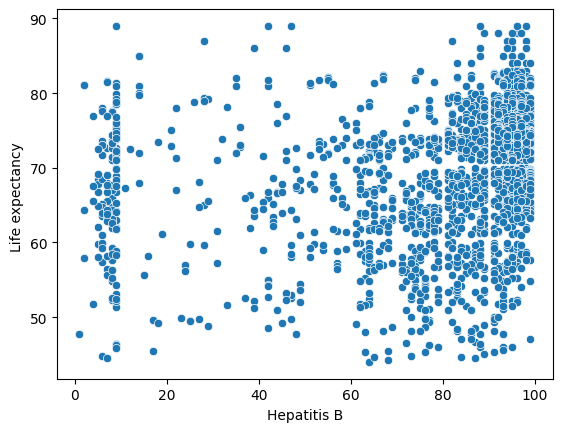

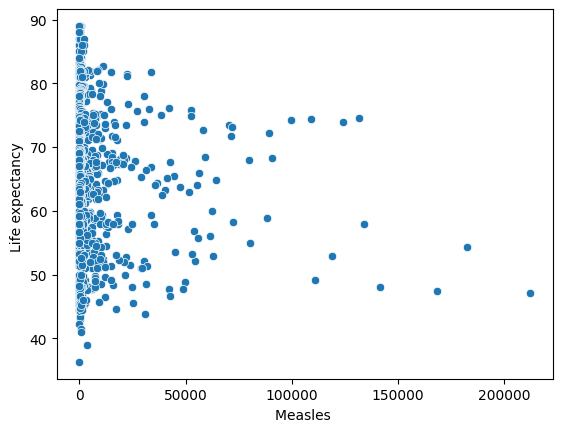

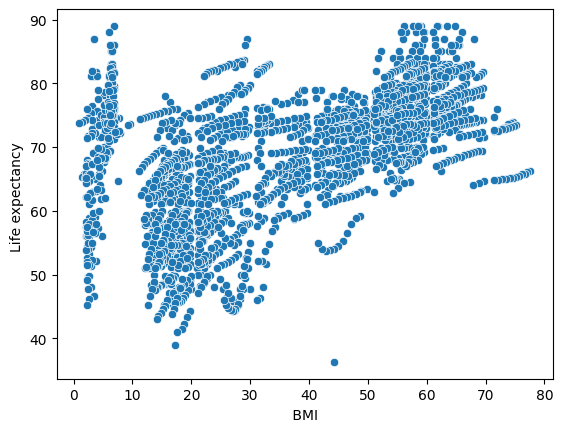

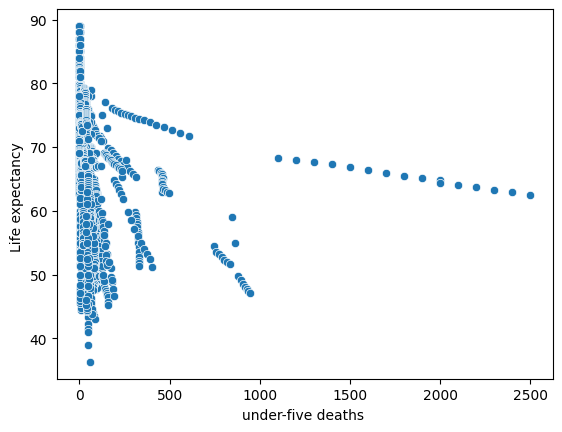

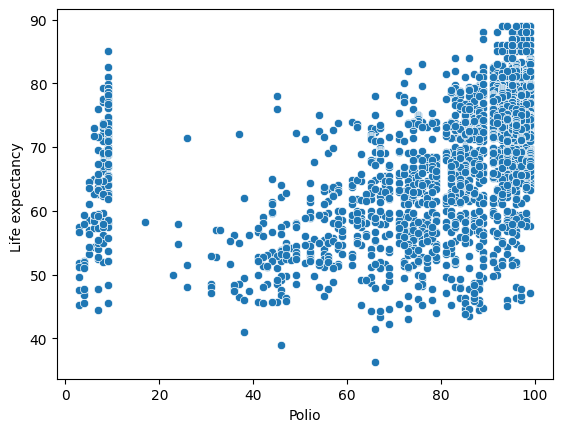

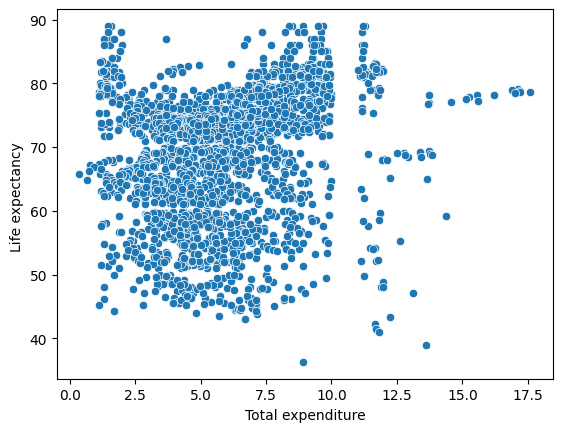

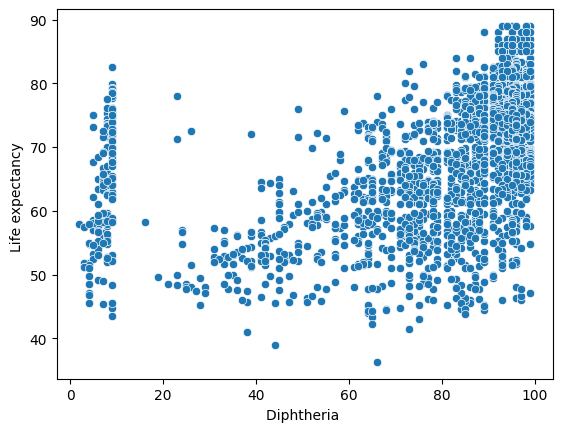

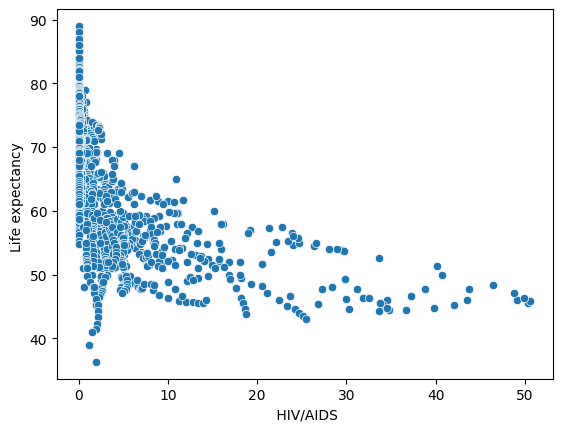

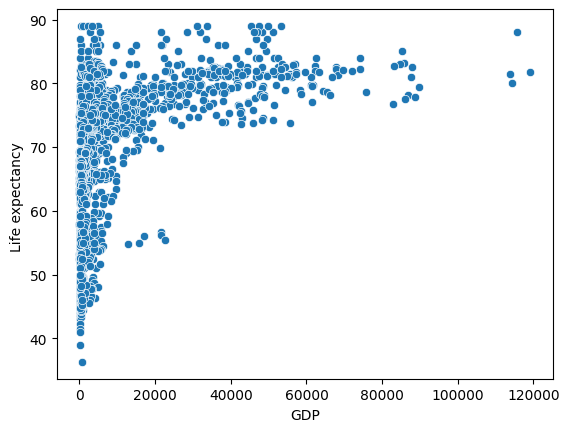

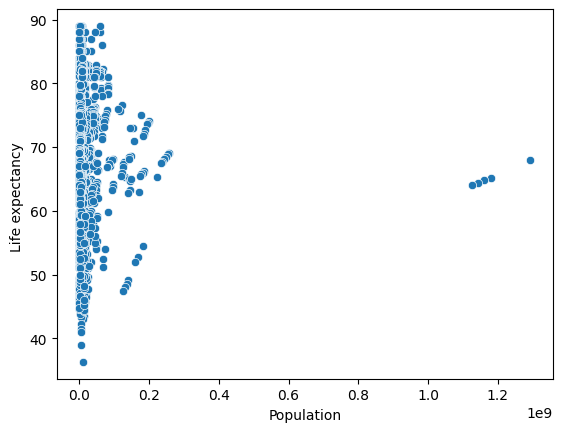

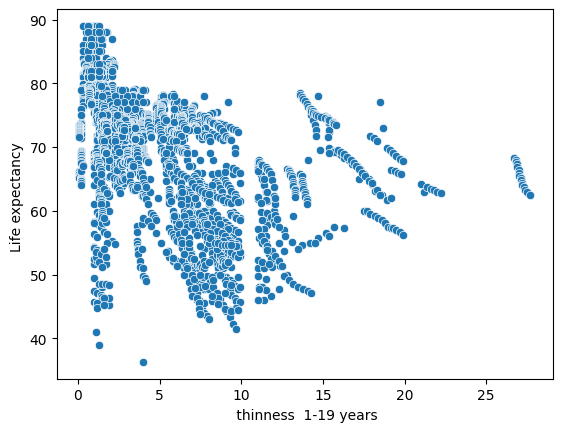

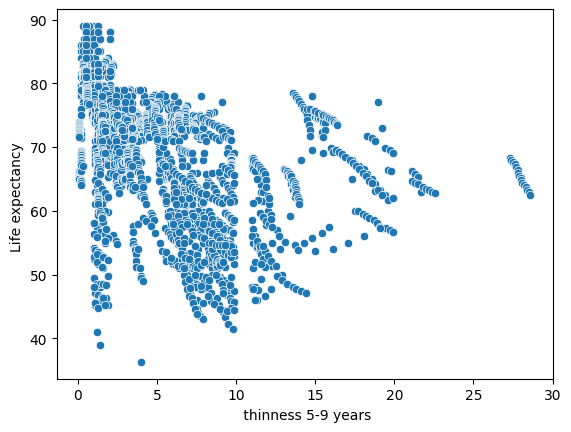

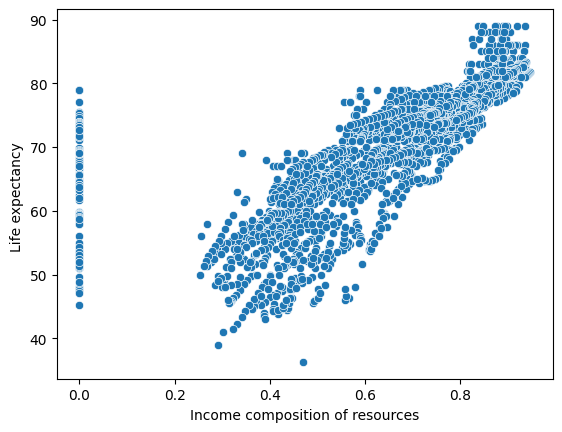

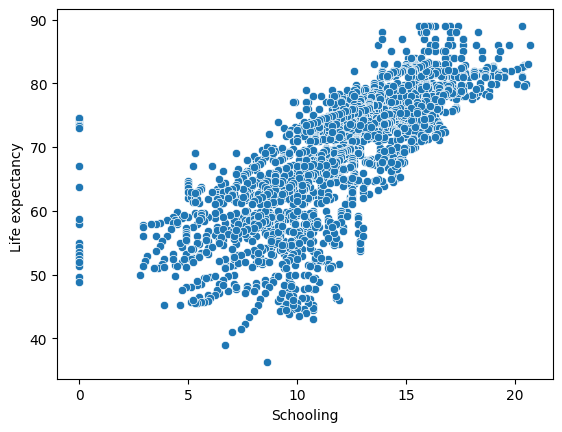

In [ ]:
# CORRELATION ANALYSIS
# This is a bi-variant(two) analysis, where we check the relationship between two columns
# How does Blood Sugar(1) affect Diabetes(2)
# How does Adult Mortality(1) affect Life Expenctancy(2)

# Correlation is measured in range between 0 and 1

# We have two types of Correlation:
# a) POSITIVE CORRELATION: Increase in one variable leads to increase in the other variable and Vice Versa
# E,g Increase in the Country's Exports(1) leads to Increase in thier GDP(2)
# E,g Schooling and Life Expenctancy have a Positive Correlation.

# b) NEGATIVE CORRELATION: Increase in one variable leads to Decrease in the other variable and vice versa
# Increase in a country's dependant population(1) leads to decrease in the GDP(2) e,g India
# Increase Adult Mortality(1) lead to Decrease in the Life Expenctancy(2)

# To visualize correlation we can work with:
# a) Scatter Plots
# b) Heatmaps

sns.scatterplot(data = data, x= 'Schooling', y = 'Life expectancy ')
plt.title('Adult Mortality vs Life Expectancy')
plt.show()


for i in data.select_dtypes(include='number').columns:
       sns.scatterplot(data=data,x=i,y='Life expectancy ')
       plt.show()




In [ ]:
#  correlation with heatmap to interpret the realation and multicollinarity
data.select_dtypes(include='number').corr()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
Year,1.000000,0.170033,-0.079052,-0.037415,-0.052990,0.031400,0.104333,-0.082493,0.108974,-0.042937,0.094158,0.090740,0.134337,-0.139741,0.101620,0.016969,-0.047876,-0.050929,0.243468,0.209400
Life expectancy,0.170033,1.000000,-0.696359,-0.196557,0.404877,0.381864,0.256762,-0.157586,0.567694,-0.222529,0.465556,0.218086,0.479495,-0.556556,0.461455,-0.021538,-0.477183,-0.471584,0.724776,0.751975
Adult Mortality,-0.079052,-0.696359,1.000000,0.078756,-0.195848,-0.242860,-0.162476,0.031176,-0.387017,0.094146,-0.274823,-0.115281,-0.275131,0.523821,-0.296049,-0.013647,0.302904,0.308457,-0.457626,-0.454612
infant deaths,-0.037415,-0.196557,0.078756,1.000000,-0.115638,-0.085612,-0.223566,0.501128,-0.227279,0.996629,-0.170689,-0.128616,-0.175171,0.025231,-0.108427,0.556801,0.465711,0.471350,-0.145139,-0.193720
Alcohol,-0.052990,0.404877,-0.195848,-0.115638,1.000000,0.341285,0.087549,-0.051827,0.330408,-0.112370,0.221734,0.296942,0.222020,-0.048845,0.354712,-0.035252,-0.428795,-0.417414,0.450040,0.547378
percentage expenditure,0.031400,0.381864,-0.242860,-0.085612,0.341285,1.000000,0.016274,-0.056596,0.228700,-0.087852,0.147259,0.174420,0.143624,-0.097857,0.899373,-0.025662,-0.251369,-0.252905,0.381952,0.389687
Hepatitis B,0.104333,0.256762,-0.162476,-0.223566,0.087549,0.016274,1.000000,-0.120529,0.150380,-0.233126,0.486171,0.058280,0.611495,-0.112675,0.083903,-0.123321,-0.120429,-0.124960,0.199549,0.231117
Measles,-0.082493,-0.157586,0.031176,0.501128,-0.051827,-0.056596,-0.120529,1.000000,-0.175977,0.507809,-0.136166,-0.106241,-0.141882,0.030899,-0.076466,0.265966,0.224808,0.221072,-0.129568,-0.137225
BMI,0.108974,0.567694,-0.387017,-0.227279,0.330408,0.228700,0.150380,-0.175977,1.000000,-0.237669,0.284569,0.242503,0.283147,-0.243717,0.301557,-0.072301,-0.532025,-0.538911,0.508774,0.546961
under-five deaths,-0.042937,-0.222529,0.094146,0.996629,-0.112370,-0.087852,-0.233126,0.507809,-0.237669,1.000000,-0.188720,-0.130148,-0.195668,0.038062,-0.112081,0.544423,0.467789,0.472263,-0.163305,-0.209373


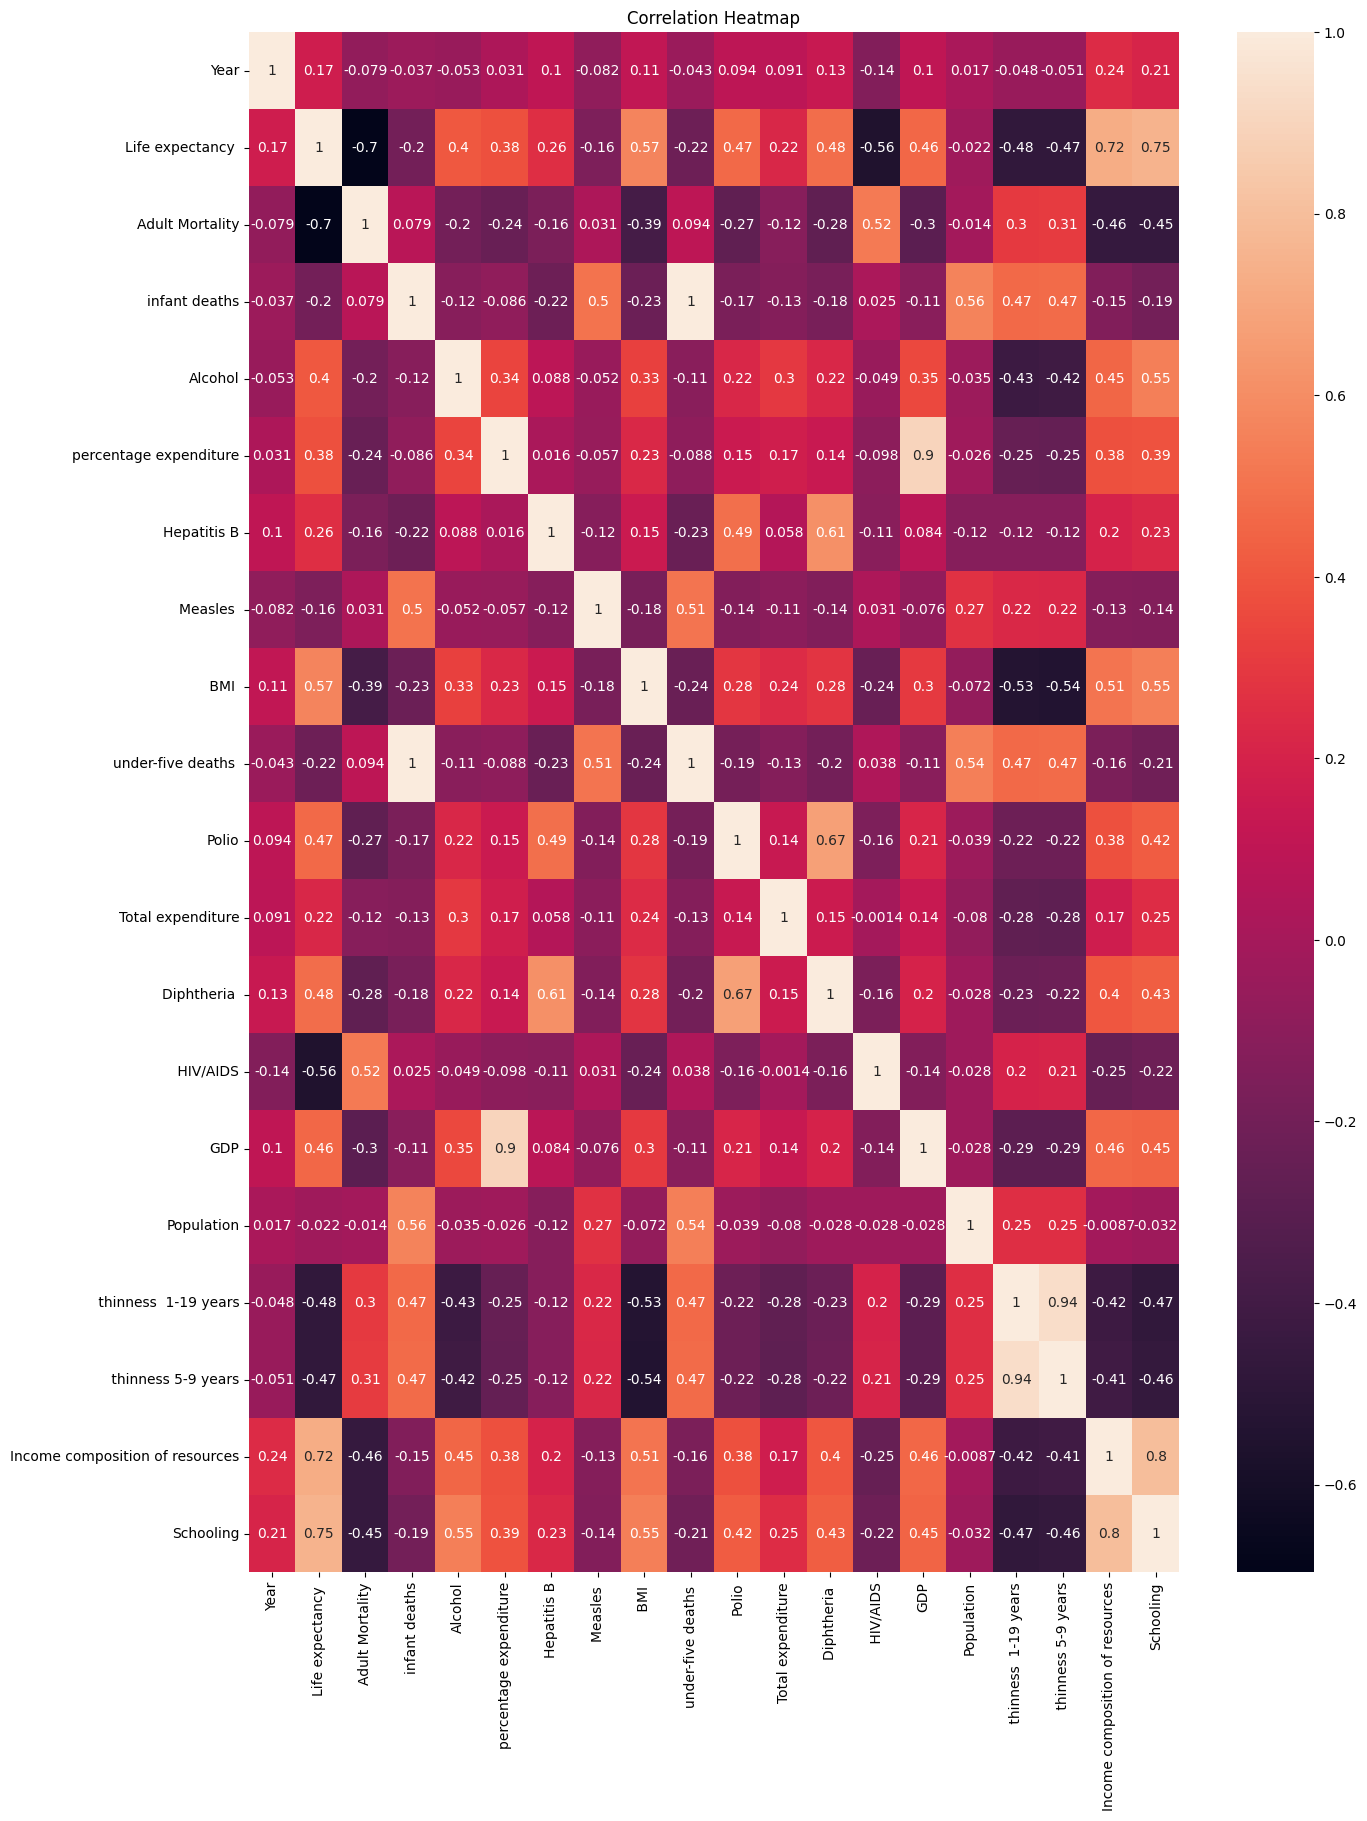

In [ ]:
plt.figure(figsize=(15,20))
sns.heatmap(data.select_dtypes(include='number').corr(), annot=True)
plt.title('Correlation Heatmap')
plt.show()

## 5. Handling Missing Values

In [ ]:
# check missing values

data.isnull().sum()

# choose the method of inputting missing value
# E,g Numerical ->  mean, median or KNNInputer
# Discreate and Categorical:Life Expectancy and Adult Mortality(Missing Values are filled by the Mode)
# Continous:Other Numerical we fill by the Mode.

data['Life expectancy '].mean()

# a) Filling the Missing Records -> fill_na()
# We normally use the fill_na(value, commit)
data['Life expectancy '].fillna(data['Life expectancy '].mean(), inplace=True)
data['Adult Mortality'].fillna(data['Adult Mortality'].mean(), inplace=True)
data['Alcohol'].fillna(data['Alcohol'].mean(), inplace=True)


# Numerical Data
for i in [' BMI ', "Polio", "Income composition of resources", "Hepatitis B", "Total expenditure", "GDP", "Schooling"]:
  data[i].fillna(data[i].mean(), inplace=True)


# b)Dropping the Empties -> drop_na(commit)
data.dropna(inplace=True)

# c) Imputation Method -> Machine Learning


data.isnull().sum()

,0
Country,0
Year,0
Status,0
Life expectancy,0
Adult Mortality,0
infant deaths,0
Alcohol,0
percentage expenditure,0
Hepatitis B,0
Measles,0


## Removing Outliers

In [ ]:
# Detecting Outliers -> Box Plot
# Remove the Outliers -> Winsorization –
#  Instead of removing outliers, extreme values are replaced with upper or lower percentile values.

def remove_outliers(col):
    q1, q3 = np.percentile(col, [0.25, 0.75])
    iqr = q3-q1
    lw = q1-(1.5*iqr)
    uw = q3+(1.5*iqr)
    return lw, uw

remove_outliers(data['Schooling'])

(1.724375, 4.859375)

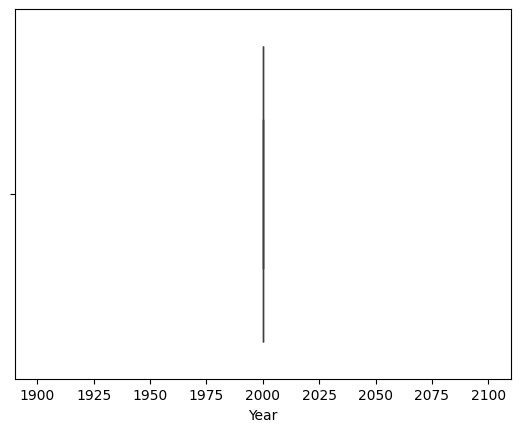

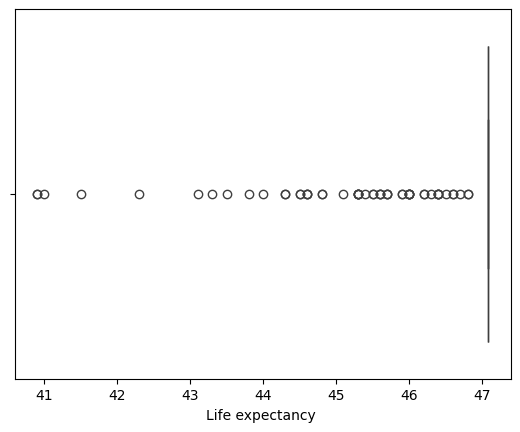

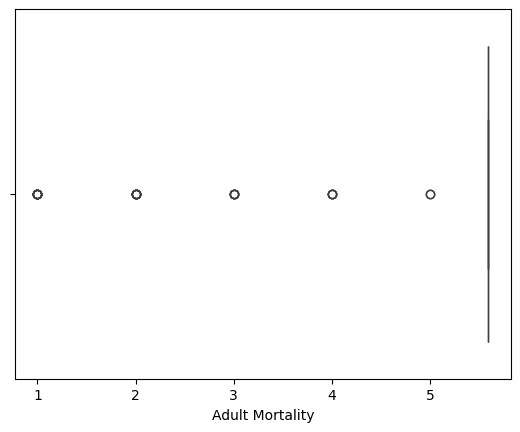

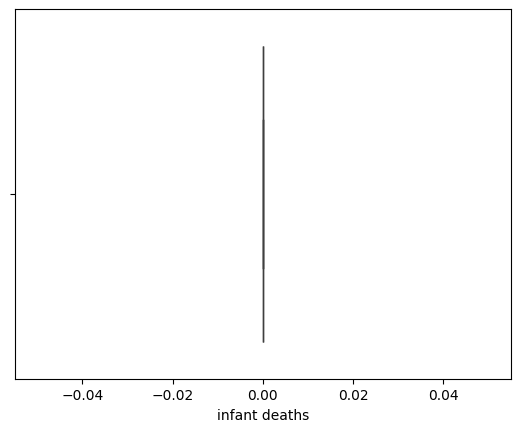

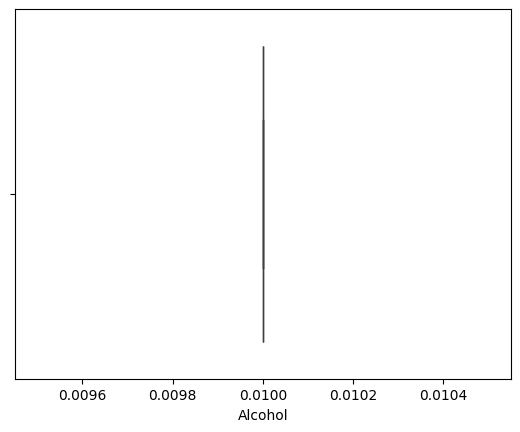

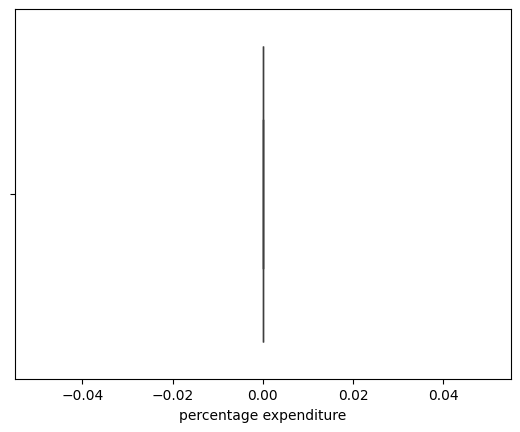

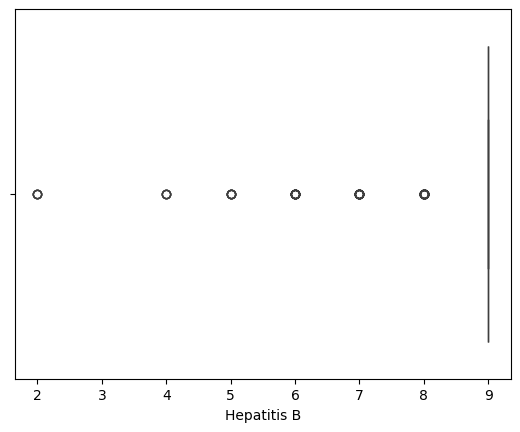

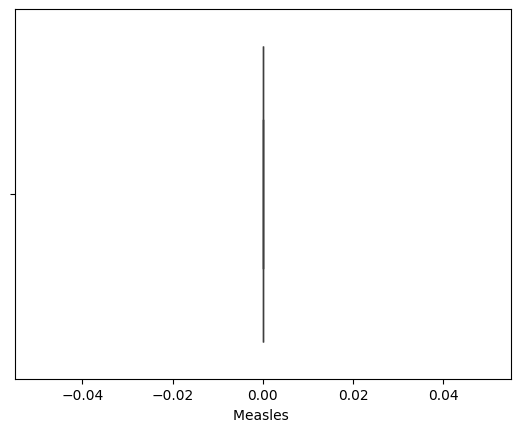

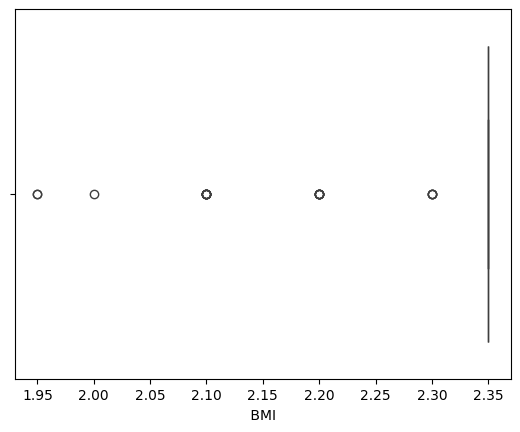

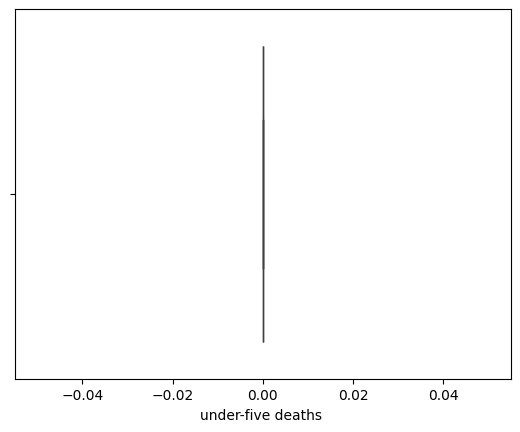

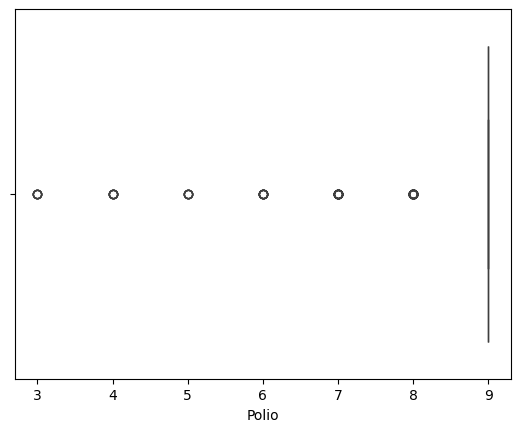

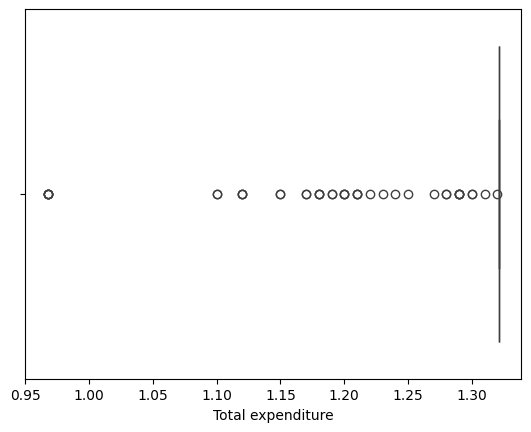

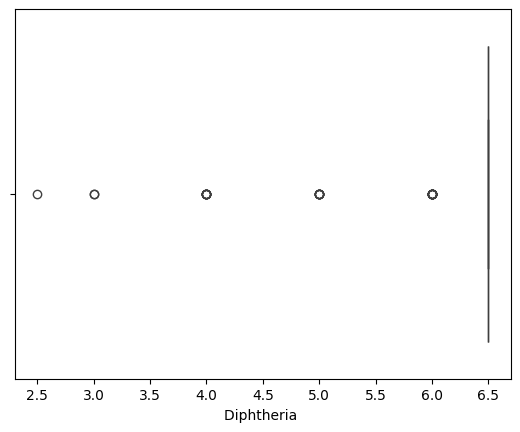

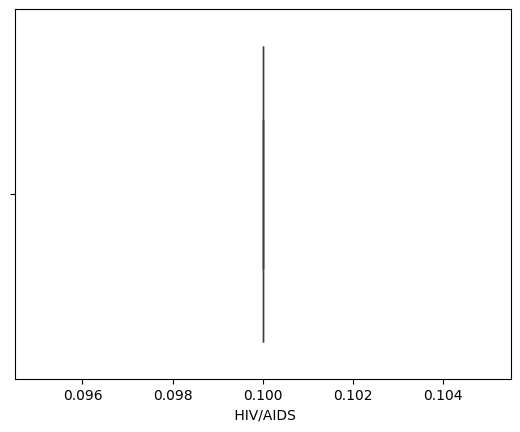

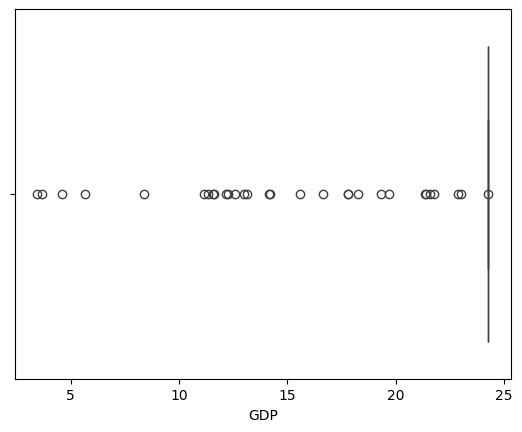

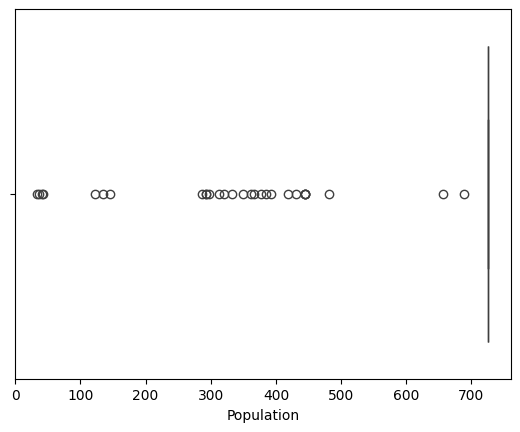

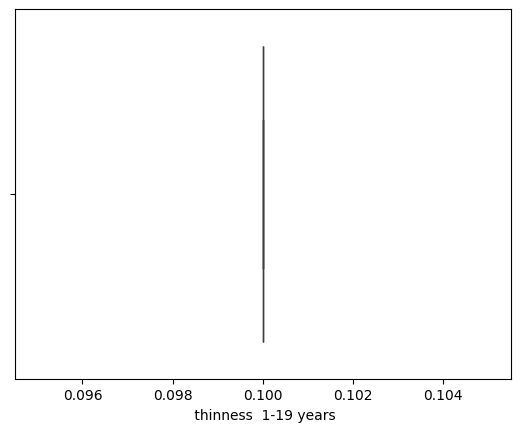

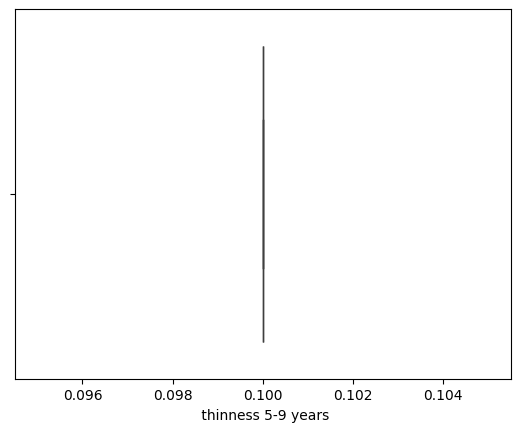

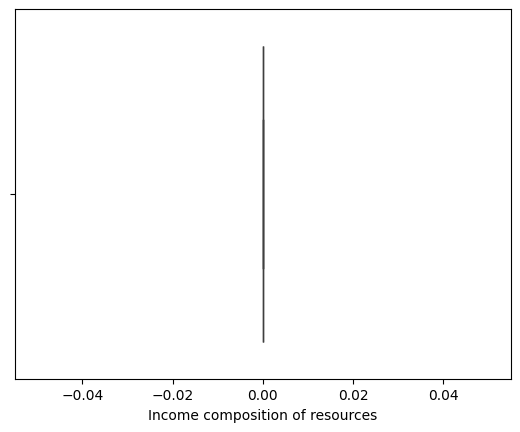

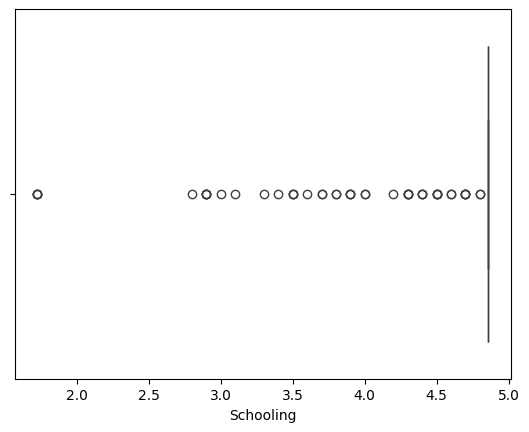

In [ ]:
# Remove outliers
for i in data.select_dtypes(include='number').columns:
  lw, uw = remove_outliers(data[i])
  data[i] = np.where(data[i]<lw, lw, data[i])
  data[i] = np.where(data[i]>uw, uw, data[i])
  sns.boxplot(data=data,x=i)
  plt.show()




<Axes: >

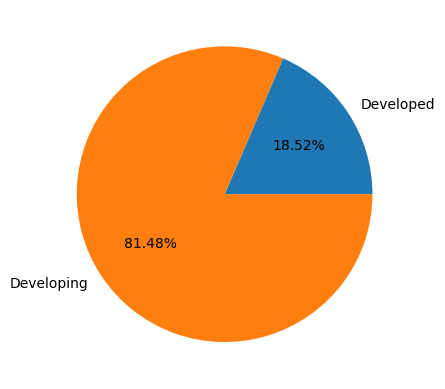

In [ ]:
# Encoding: Process of Converting Categorical Columns into Numerical Labels
# We Normally call the groupby() in categorical columns
data.groupby('Status').size().plot(kind='pie', autopct='%1.2F%%')

In [ ]:
# Label Encoding -> replace({key:value}, commit)
data['Status'].replace({
    'Developed':1,
    'Developing':0
}, inplace=True)

data.groupby('Status').size()

,0
Status,
0,1830
1,416
